# SmartConcrete AI: An End-to-End Deep Learning Suite for Strength Prediction, Benchmarking, and Green Mix Optimization.

In [1]:
!pip install tensorflow


   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.8/384.1 MB 6.9 MB/s eta 0:00:56
   ---------------------------------------- 2.1/384.1 MB 6.5 MB/s eta 0:00:59
   ---------------------------------------- 3.4/384.1 MB 6.1 MB/s eta 0:01:03
    --------------------------------------- 5.0/384.1 MB 6.4 MB/s eta 0:00:59
    --------------------------------------- 6.3/384.1 MB 6.4 MB/s eta 0:00:59
    --------------------------------------- 7.6/384.1 MB 6.6 MB/s eta 0:00:57
    --------------------------------------- 9.4/384.1 MB 6.8 MB/s eta 0:00:55
   - -------------------------------------- 11.5/384.1 MB 7.2 MB/s eta 0:00:52
   - -------------------------------------- 13.6/384.1 MB 7.5 MB/s eta 0:00:50
   - -------------------------------------- 16.0/384.1 MB 7.8 MB/s eta 0:00:47
   - -------------------------------------- 17.8/384.1 MB 8.0 MB/s eta 0:00:46
   - -------------------------------------- 17.8/384.1 MB 8.0 MB/s 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\lenovo\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
from tensorflow import keras

print("TensorFlow Version:", tf.__version__)
print("Keras Version:", keras.__version__)


TensorFlow Version: 2.22.0-rc0
Keras Version: 3.16.0.dev2026102304


In [3]:
# ==============================================================================
# IMPORT REQUIRED LIBRARIES AND ENVIRONMENT SETUP
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML libraries for benchmarking and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import joblib  # To save the scaler and classical ML models

# Deep Learning libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Check TensorFlow configuration
print("TensorFlow Version:", tf.__version__)
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))


TensorFlow Version: 2.22.0-rc0
Num GPUs Available: 0


In [4]:
# ==============================================================================
# LOAD DATASET USING ABSOLUTE WINDOWS PATH AND INSPECT
# ==============================================================================

# Using 'r' before the string to handle Windows backslashes properly
data_path = r"C:\Users\lenovo\OneDrive\Desktop\Smart Concrete AI\data\raw\concrete_data.csv"

# Load the CSV file into a pandas DataFrame
df = pd.read_csv(data_path)

# Display the total rows and columns (Shape)
print(f"Dataset Shape: {df.shape}")

# View the first 5 records of the dataset
df.head()


Dataset Shape: (1030, 9)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [5]:
# ==============================================================================
# CHECK DATA TYPES, MISSING VALUES, AND DUPLICATES
# ==============================================================================

# Check the data type of each column and find if there are any missing values
print("--- Data Info and Missing Values ---")
print(df.info())

# Check the exact count of missing values in each column
print("\n--- Missing Values Count per Column ---")
print(df.isnull().sum())

# Check for duplicate rows in the dataset
duplicate_count = df.duplicated().sum()
print(f"\nTotal Duplicate Rows Found: {duplicate_count}")


--- Data Info and Missing Values ---
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1030 non-null   float64
 1   Blast Furnace Slag  1030 non-null   float64
 2   Fly Ash             1030 non-null   float64
 3   Water               1030 non-null   float64
 4   Superplasticizer    1030 non-null   float64
 5   Coarse Aggregate    1030 non-null   float64
 6   Fine Aggregate      1030 non-null   float64
 7   Age                 1030 non-null   int64  
 8   Strength            1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB
None

--- Missing Values Count per Column ---
Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

To

In [6]:
# ==============================================================================
# DATA CLEANING - REMOVE DUPLICATE RECORDS
# ==============================================================================

# Drop duplicates and keep the first occurrence
df_cleaned = df.drop_duplicates(keep='first')

# Reset index to ensure smooth data processing later
df_cleaned = df_cleaned.reset_index(drop=True)

# Print the new shape to verify changes
print(f"Original Dataset Shape: {df.shape}")
print(f"Cleaned Dataset Shape: {df_cleaned.shape}")
print(f"Total Rows Removed: {df.shape[0] - df_cleaned.shape[0]}")


Original Dataset Shape: (1030, 9)
Cleaned Dataset Shape: (1005, 9)
Total Rows Removed: 25


In [7]:
# ==============================================================================
# SAVE CLEANED DATASET TO THE CLEANED DATA FOLDER
# ==============================================================================

# Define the accurate path for the cleaned data folder
cleaned_data_path = r"C:\Users\lenovo\OneDrive\Desktop\Smart Concrete AI\data\cleaned\concrete_cleaned.csv"

# Export the cleaned DataFrame to a new CSV file without the index column
df_cleaned.to_csv(cleaned_data_path, index=False)

print(f"Success! Cleaned dataset successfully saved at:\n{cleaned_data_path}")


Success! Cleaned dataset successfully saved at:
C:\Users\lenovo\OneDrive\Desktop\Smart Concrete AI\data\cleaned\concrete_cleaned.csv


In [1]:
# ==============================================================================
# IMPORT PLOTTING LIBRARIES AND SET VISUAL THEME
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style for all upcoming charts
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]

print("Plotting libraries imported and styles configured successfully!")


Plotting libraries imported and styles configured successfully!


In [2]:
# ==============================================================================
# LOAD THE CLEANED DATASET FROM THE 'CLEANED' FOLDER
# ==============================================================================

# Accurate path to the cleaned folder where data was saved yesterday
cleaned_data_path = r"C:\Users\lenovo\OneDrive\Desktop\Smart Concrete AI\data\cleaned\concrete_cleaned.csv"

# Load the data
df = pd.read_csv(cleaned_data_path)

# Verify the shape to confirm it has 1005 unique rows
print(f"Cleaned Data Loaded Successfully! Shape: {df.shape}")


Cleaned Data Loaded Successfully! Shape: (1005, 9)


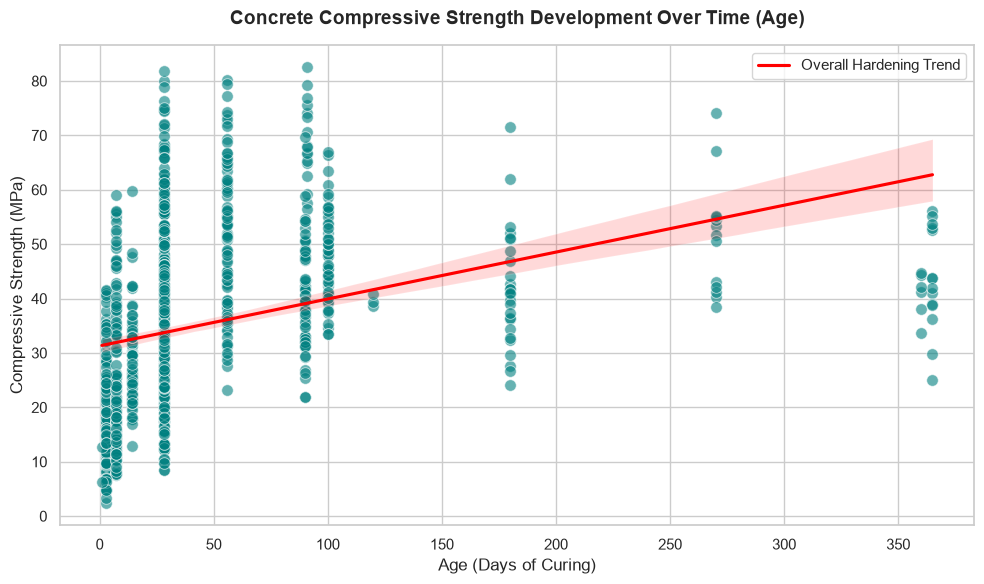

--- Distribution of Data Across Curing Milestones (Age) ---
Age
1        2
3      129
7      122
14      62
28     419
56      86
90      54
91      17
100     52
120      3
180     26
270     13
360      6
365     14
Name: count, dtype: int64


In [3]:
# ==============================================================================
# EXPLORATORY DATA ANALYSIS - AGE VS STRENGTH HARDENING ANALYSIS
# ==============================================================================

# Create a scatter plot to observe how Concrete Strength changes over time (Age)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Age', y='Strength', alpha=0.6, color='teal', edgecolor='w', s=70)

# Add a trend line (Regression line) using Seaborn's regplot without overlapping data
sns.regplot(data=df, x='Age', y='Strength', scatter=False, color='red', label='Overall Hardening Trend')

# Setting up labels and titles for clarity
plt.title('Concrete Compressive Strength Development Over Time (Age)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Age (Days of Curing)', fontsize=12)
plt.ylabel('Compressive Strength (MPa)', fontsize=12)
plt.legend()
plt.tight_layout()

# Display the plot
plt.show()

# Print specific insights about data distribution based on typical concrete curing milestones
print("--- Distribution of Data Across Curing Milestones (Age) ---")
print(df['Age'].value_counts().sort_index())


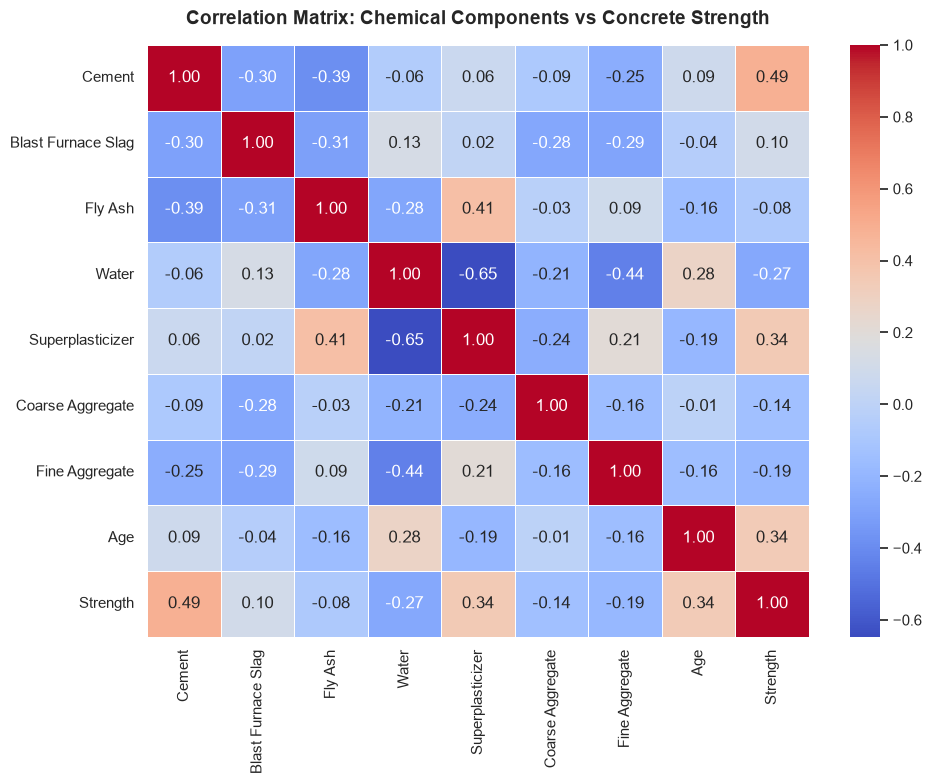

--- Correlation of Features with Concrete Strength ---
Strength              1.000000
Cement                0.488283
Superplasticizer      0.344209
Age                   0.337367
Blast Furnace Slag    0.103374
Fly Ash              -0.080648
Coarse Aggregate     -0.144717
Fine Aggregate       -0.186448
Water                -0.269624
Name: Strength, dtype: float64


In [4]:
# ==============================================================================
# EXPLORATORY DATA ANALYSIS - CHEMICAL CORRELATION HEATMAP
# ==============================================================================

# Calculate the Pearson correlation matrix for all features
correlation_matrix = df.corr()

# Create a heatmap to visualize relationships between materials and strength
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

# Adding proper titles and layouts
plt.title('Correlation Matrix: Chemical Components vs Concrete Strength', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()

# Display the heatmap
plt.show()

# Print specific statistical insights about the highest impacting features
strength_corr = correlation_matrix['Strength'].sort_values(ascending=False)
print("--- Correlation of Features with Concrete Strength ---")
print(strength_corr)


In [6]:
# ==============================================================================
# FEATURE ENGINEERING - DATA SPLITTING FOR BENCHMARKING AND MODELING
# ==============================================================================

# Importing train_test_split explicitly to fix the NameError
from sklearn.model_selection import train_test_split

# Separate features (X) and target variable (y)
X = df.drop(columns=['Strength'])
y = df['Strength']

# Split the dataset into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print the shapes of the splits to confirm correct distribution
print("--- Data Splitting Configurations ---")
print(f"Full Dataset Features Shape : {X.shape}")
print(f"Training Features Shape       : {X_train.shape}")
print(f"Testing Features Shape        : {X_test.shape}")
print(f"Training Target Shape         : {y_train.shape}")
print(f"Testing Target Shape          : {y_test.shape}")


--- Data Splitting Configurations ---
Full Dataset Features Shape : (1005, 8)
Training Features Shape       : (804, 8)
Testing Features Shape        : (201, 8)
Training Target Shape         : (804,)
Testing Target Shape          : (201,)


In [7]:
# ==============================================================================
# MODEL BENCHMARKING - LINEAR REGRESSION AND RANDOM FOREST
# ==============================================================================

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Initialize the models
lr_model = LinearRegression()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# 2. Train the models on the unscaled training data
lr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# 3. Make predictions on the testing data
lr_preds = lr_model.predict(X_test)
rf_preds = rf_model.predict(X_test)

# 4. Evaluate and display metrics
print("==================================================")
print("   CLASSICAL MACHINE LEARNING BENCHMARK RESULTS   ")
print("==================================================")
print(f"Linear Regression R2 Score : {r2_score(y_test, lr_preds):.4f}")
print(f"Linear Regression MAE      : {mean_absolute_error(y_test, lr_preds):.4f} MPa")
print(f"Linear Regression RMSE     : {np.sqrt(mean_squared_error(y_test, lr_preds)):.4f} MPa")
print("--------------------------------------------------")
print(f"Random Forest R2 Score     : {r2_score(y_test, rf_preds):.4f}")
print(f"Random Forest MAE          : {mean_absolute_error(y_test, rf_preds):.4f} MPa")
print(f"Random Forest RMSE         : {np.sqrt(mean_squared_error(y_test, rf_preds)):.4f} MPa")
print("==================================================")


   CLASSICAL MACHINE LEARNING BENCHMARK RESULTS   
Linear Regression R2 Score : 0.5802
Linear Regression MAE      : 8.8953 MPa
Linear Regression RMSE     : 11.1913 MPa
--------------------------------------------------
Random Forest R2 Score     : 0.9076
Random Forest MAE          : 3.4841 MPa
Random Forest RMSE         : 5.2496 MPa


In [8]:
# ==============================================================================
# FEATURE SCALING USING STANDARD SCALER FOR NEURAL NETWORK
# ==============================================================================

from sklearn.preprocessing import StandardScaler
import joblib

# 1. Initialize the StandardScaler
scaler = StandardScaler()

# 2. Fit on training data and transform both training and testing sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Save the scaler object to use inside our Streamlit application later
scaler_backend_path = r"C:\Users\lenovo\OneDrive\Desktop\Smart Concrete AI\models\standard_scaler.pkl"
joblib.dump(scaler, scaler_backend_path)

print("--- Feature Scaling Verification ---")
print(f"Scaled Training Shape : {X_train_scaled.shape}")
print(f"Scaled Testing Shape  : {X_test_scaled.shape}")
print(f"Scaler saved successfully at: {scaler_backend_path}")


--- Feature Scaling Verification ---
Scaled Training Shape : (804, 8)
Scaled Testing Shape  : (201, 8)
Scaler saved successfully at: C:\Users\lenovo\OneDrive\Desktop\Smart Concrete AI\models\standard_scaler.pkl


In [10]:
# ==============================================================================
# CORE DEEP NEURAL NETWORK ARCHITECTURE DESIGN (KERAS 3 STANDARD)
# ==============================================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

# 1. Initialize the Sequential model layer stack
nn_model = Sequential()

# 2. Add explicit Input layer according to Keras 3 guidelines
nn_model.add(Input(shape=(X_train_scaled.shape[1],)))

# 3. First Hidden Layer (64 Dense Neurons with ReLU activation)
nn_model.add(Dense(64, activation='relu'))
nn_model.add(Dropout(0.1))  # Regularization to prevent overfitting

# 4. Second Hidden Layer (32 Dense Neurons with ReLU activation)
nn_model.add(Dense(32, activation='relu'))

# 5. Third Hidden Layer (16 Dense Neurons with ReLU activation)
nn_model.add(Dense(16, activation='relu'))

# 6. Output Layer (1 Neuron for Continuous Strength Value Regression)
nn_model.add(Dense(1))  # No activation for regression tasks

# 7. Print Model Architecture Summary details
nn_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 64)                  │             576 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# ==============================================================================
# MODEL COMPILATION AND EARLY STOPPING CONFIGURATION
# ==============================================================================

# Explicitly importing EarlyStopping to fix the NameError
from tensorflow.keras.callbacks import EarlyStopping

# 1. Compile the neural network with Adam optimizer and MSE loss
nn_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# 2. Configure EarlyStopping callback to monitor validation loss
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

print("Neural Network compiled successfully with Adam optimizer!")
print("EarlyStopping callback configured and NameError resolved.")


Neural Network compiled successfully with Adam optimizer!
EarlyStopping callback configured and NameError resolved.


In [13]:
# ==============================================================================
# TRAINING THE NEURAL NETWORK WITH VALIDATION SPLIT AND CALLBACKS
# ==============================================================================

# Train the model and save the history parameters
# We use 20% of the training data as a validation subset to monitor learning progress
history = nn_model.fit(
    X_train_scaled, 
    y_train, 
    validation_split=0.2, 
    epochs=150, 
    batch_size=16, 
    callbacks=[early_stop],
    verbose=1
)

print("\nNeural Network training process completed successfully!")


Epoch 1/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - loss: 1427.8590 - mae: 34.2517 - val_loss: 1451.7871 - val_mae: 34.6773
Epoch 2/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1200.6835 - mae: 30.8790 - val_loss: 1035.0288 - val_mae: 28.2877
Epoch 3/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 536.5910 - mae: 18.6161 - val_loss: 248.2549 - val_mae: 12.6664
Epoch 4/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 216.8329 - mae: 11.8269 - val_loss: 182.8616 - val_mae: 11.0818
Epoch 5/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 183.4288 - mae: 11.0499 - val_loss: 167.5217 - val_mae: 10.7614
Epoch 6/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 171.9825 - mae: 10.7509 - val_loss: 161.0546 - val_mae: 10.5961
Epoch 7/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 160.7512 - mae: 10.3373 - val_loss: 155.1052 - val_mae: 10.3947
Epoch 8/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 155.5405 - mae: 10.1781 - val_loss: 150.5448 - val_mae: 10.2235
Epoch 9

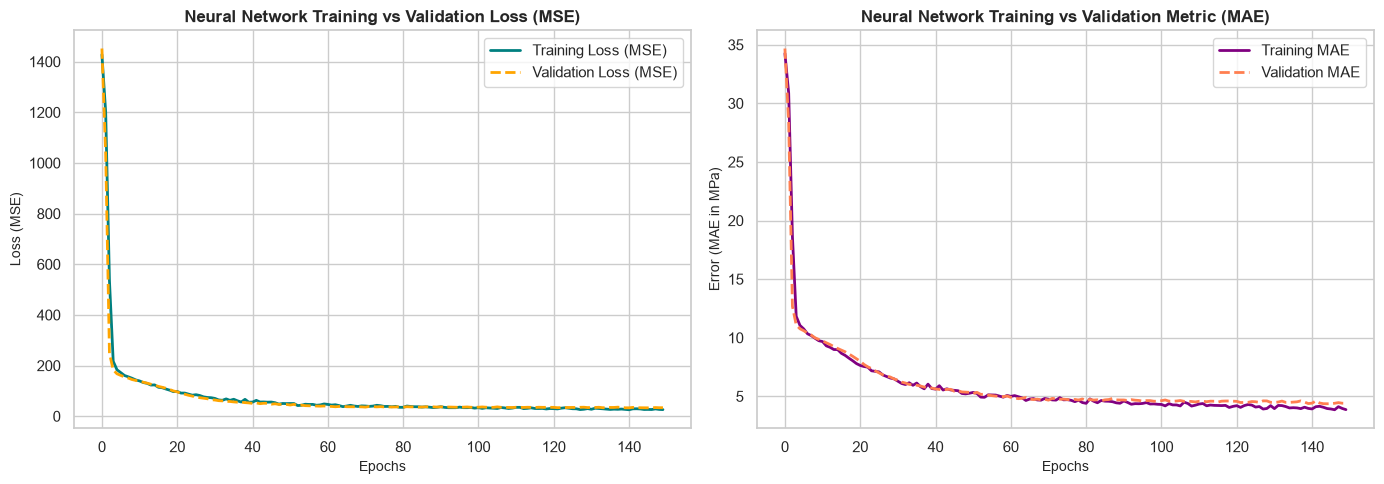

In [14]:
# ==============================================================================
# MODEL PERFORMANCE EVALUATION - PLOTTING TRAINING HISTORY
# ==============================================================================

# Create a figure to plot MSE Loss and MAE Metrics side by side
plt.figure(figsize=(14, 5))

# Plot 1: Mean Squared Error (Loss) Curves
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss (MSE)', color='teal', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', color='orange', linestyle='--', linewidth=2)
plt.title('Neural Network Training vs Validation Loss (MSE)', fontsize=12, fontweight='bold')
plt.xlabel('Epochs', fontsize=10)
plt.ylabel('Loss (MSE)', fontsize=10)
plt.legend()

# Plot 2: Mean Absolute Error (MAE) Curves
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE', color='purple', linewidth=2)
plt.plot(history.history['val_mae'], label='Validation MAE', color='coral', linestyle='--', linewidth=2)
plt.title('Neural Network Training vs Validation Metric (MAE)', fontsize=12, fontweight='bold')
plt.xlabel('Epochs', fontsize=10)
plt.ylabel('Error (MAE in MPa)', fontsize=10)
plt.legend()

plt.tight_layout()
plt.show()


In [15]:
# ==============================================================================
# MODEL EVALUATION ON TEST SET AND MODEL CHECKPOINT EXPORT
# ==============================================================================

# 1. Generate strength predictions on the scaled testing subset
nn_preds = nn_model.predict(X_test_scaled).flatten()

# 2. Calculate evaluation metrics for the Neural Network
nn_r2 = r2_score(y_test, nn_preds)
nn_mae = mean_absolute_error(y_test, nn_preds)
nn_rmse = np.sqrt(mean_squared_error(y_test, nn_preds))

print("==================================================")
print("     DEEP NEURAL NETWORK EVALUATION RESULTS       ")
print("==================================================")
print(f"Neural Network R2 Score : {nn_r2:.4f}")
print(f"Neural Network MAE      : {nn_mae:.4f} MPa")
print(f"Neural Network RMSE     : {nn_rmse:.4f} MPa")
print("==================================================\n")

# 3. Save the trained neural network architecture and weights for Streamlit deployment
# Keras 3 format prefers saving with the '.keras' extension instead of old '.h5'
nn_model_backend_path = r"C:\Users\lenovo\OneDrive\Desktop\Smart Concrete AI\models\concrete_nn_model.keras"
nn_model.save(nn_model_backend_path)

print(f"Success! Trained Neural Network saved successfully at:\n{nn_model_backend_path}")


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
     DEEP NEURAL NETWORK EVALUATION RESULTS       
Neural Network R2 Score : 0.8883
Neural Network MAE      : 4.3704 MPa
Neural Network RMSE     : 5.7723 MPa

Success! Trained Neural Network saved successfully at:
C:\Users\lenovo\OneDrive\Desktop\Smart Concrete AI\models\concrete_nn_model.keras


In [16]:
# ==============================================================================
# ECO-FRIENDLY RECYCLE MIX OPTIMIZATION SIMULATION
# ==============================================================================

# 1. Define a standard high-cement layout template row from data
# Form: [Cement, Slag, FlyAsh, Water, Super plasticizer, CoarseAgg, FineAgg, Age]
standard_mix = np.array([[540.0, 0.0, 0.0, 162.0, 2.5, 1040.0, 676.0, 28]])

# 2. Define an engineered Eco-Friendly/Green alternative layout mix
# Action: Reduced Cement by ~35%, increased Slag/FlyAsh to balance aggregate volume
green_mix = np.array([[350.0, 95.0, 95.0, 162.0, 5.0, 1040.0, 676.0, 28]])

# 3. Transform inputs using the pre-trained scaler object saved in Phase 3
standard_scaled = scaler.transform(standard_mix)
green_scaled = scaler.transform(green_mix)

# 4. Predict strength values using the trained core neural network graph engine
standard_pred = nn_model.predict(standard_scaled).flatten()[0]
green_pred = nn_model.predict(green_scaled).flatten()[0]

# 5. Display comparison analytics output
print("==================================================")
print("     SUSTAINABLE ECO-MIX SIMULATION ANALYSIS      ")
print("==================================================")
print(f"Standard High-Cement Mix Predicted Strength : {standard_pred:.2f} MPa")
print(f"Eco-Green Engineered Mix Predicted Strength : {green_pred:.2f} MPa")
print("--------------------------------------------------")
strength_diff = green_pred - standard_pred
cement_reduction = ((540.0 - 350.0) / 540.0) * 100

print(f"Cement Reduction Percentage                 : {cement_reduction:.1f}% LESS Carbon")
print(f"Variance / Strength Difference Delta        : {strength_diff:.2f} MPa")
print("==================================================")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step

C:\Users\lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
     SUSTAINABLE ECO-MIX SIMULATION ANALYSIS      
Standard High-Cement Mix Predicted Strength : 71.41 MPa
Eco-Green Engineered Mix Predicted Strength : 60.08 MPa
--------------------------------------------------
Cement Reduction Percentage                 : 35.2% LESS Carbon
Variance / Strength Difference Delta        : -11.33 MPa
